<a href="https://colab.research.google.com/github/ramana692/231FA04A56_MLOPS1/blob/main/External.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q pandas numpy scikit-learn mlflow fastapi uvicorn pyngrok pytest joblib

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import joblib
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display

np.random.seed(42)

print("All libraries imported successfully")

All libraries imported successfully


In [3]:

np.random.seed(42)

n = 300

data = pd.DataFrame({
    "transfer_id": range(1, n+1),

    "expected_train_delay_min":
        np.random.randint(0, 20, n),

    "platform_bus_distance_m":
        np.random.randint(50, 500, n),

    "walking_speed_mps":
        np.random.uniform(0.7, 1.8, n),

    "crowd_density":
        np.random.uniform(0.1, 0.8, n),

    "luggage_category":
        np.random.choice(
            ["None", "Small", "Medium", "Heavy"], n
        ),

    "scheduled_transfer_time_min":
        np.random.randint(5, 25, n),

    "lift_availability":
        np.random.choice(["Available", "Unavailable"], n),

    "escalator_availability":
        np.random.choice(["Available", "Unavailable"], n)
})

display(data.head())

data.to_csv("transfers_v1.csv", index=False)

print("Version 1 dataset created:", data.shape)

,transfer_id,expected_train_delay_min,platform_bus_distance_m,walking_speed_mps,crowd_density,luggage_category,scheduled_transfer_time_min,lift_availability,escalator_availability
0,1,6,330,1.676475,0.656687,Medium,10,Unavailable,Available
1,2,19,272,1.086007,0.241139,Medium,23,Available,Unavailable
2,3,14,103,0.828774,0.214559,Small,11,Available,Available
3,4,10,107,0.857291,0.214986,Medium,14,Available,Unavailable
4,5,7,372,1.537662,0.670202,Small,13,Available,Available


Version 1 dataset created: (300, 9)


In [4]:

def generate_target(df):

    effective_speed = (
        df["walking_speed_mps"] *
        (1 - 0.48 * df["crowd_density"])
    )

    effective_speed = effective_speed.clip(lower=0.25)

    walking_time = (
        df["platform_bus_distance_m"] /
        effective_speed / 60
    )

    luggage_penalty = df["luggage_category"].map({
        "None": 0,
        "Small": 0.15,
        "Medium": 0.35,
        "Heavy": 0.65
    })

    walking_time += luggage_penalty * 0.18

    walking_time += np.where(
        df["lift_availability"] == "Unavailable", 0.7, 0
    )

    walking_time += np.where(
        df["escalator_availability"] == "Unavailable", 0.35, 0
    )

    margin = (
        df["scheduled_transfer_time_min"]
        - df["expected_train_delay_min"]
        - walking_time
    )

    df["missed_connection"] = np.where(
        margin < 1.25, "Yes", "No"
    )

    return df

data = generate_target(data)

display(data.head(10))

print(data["missed_connection"].value_counts())

,transfer_id,expected_train_delay_min,platform_bus_distance_m,walking_speed_mps,crowd_density,luggage_category,scheduled_transfer_time_min,lift_availability,escalator_availability,missed_connection
0,1,6,330,1.676475,0.656687,Medium,10,Unavailable,Available,Yes
1,2,19,272,1.086007,0.241139,Medium,23,Available,Unavailable,Yes
2,3,14,103,0.828774,0.214559,Small,11,Available,Available,Yes
3,4,10,107,0.857291,0.214986,Medium,14,Available,Unavailable,No
4,5,7,372,1.537662,0.670202,Small,13,Available,Available,Yes
5,6,6,409,1.380040,0.565638,Medium,6,Unavailable,Unavailable,Yes
6,7,18,223,0.811235,0.466146,None,19,Available,Unavailable,Yes
7,8,10,329,0.792517,0.351181,Small,9,Available,Available,Yes
8,9,10,163,1.471066,0.714040,Medium,8,Available,Available,Yes
9,10,3,337,0.780039,0.374712,Heavy,24,Available,Unavailable,No


missed_connection
Yes    170
No     130
Name: count, dtype: int64


In [5]:

np.random.seed(202)

n = 350

data_v2 = pd.DataFrame({
    "transfer_id": range(301, 301+n),

    "expected_train_delay_min":
        np.random.randint(5, 36, n),

    "platform_bus_distance_m":
        np.random.randint(50, 500, n),

    "walking_speed_mps":
        np.random.uniform(0.7, 1.8, n),

    "crowd_density":
        np.random.uniform(0.55, 1.0, n),

    "luggage_category":
        np.random.choice(
            ["None", "Small", "Medium", "Heavy"], n
        ),

    "scheduled_transfer_time_min":
        np.random.randint(5, 20, n),

    "lift_availability":
        np.random.choice(
            ["Available", "Unavailable"], n, p=[0.55, 0.45]
        ),

    "escalator_availability":
        np.random.choice(
            ["Available", "Unavailable"], n, p=[0.62, 0.38]
        )
})

data_v2 = generate_target(data_v2)

data_v2.to_csv("transfers_v2_peak_hour.csv", index=False)

display(data_v2.head())

print("Version 2 dataset:", data_v2.shape)
print(data_v2["missed_connection"].value_counts())

,transfer_id,expected_train_delay_min,platform_bus_distance_m,walking_speed_mps,crowd_density,luggage_category,scheduled_transfer_time_min,lift_availability,escalator_availability,missed_connection
0,301,24,474,1.102372,0.687437,Small,11,Available,Available,Yes
1,302,28,112,1.385477,0.772460,Small,15,Available,Available,Yes
2,303,33,111,0.713660,0.937790,Heavy,19,Unavailable,Available,Yes
3,304,17,281,0.931017,0.989966,Small,10,Available,Available,Yes
4,305,13,298,0.849506,0.851731,None,18,Unavailable,Available,Yes


Version 2 dataset: (350, 10)
missed_connection
Yes    332
No      18
Name: count, dtype: int64


In [6]:

print("VERSION 1")
print(data["expected_train_delay_min"].mean())
print(data["crowd_density"].mean())

print("\nVERSION 2 - PEAK HOUR")
print(data_v2["expected_train_delay_min"].mean())
print(data_v2["crowd_density"].mean())

comparison = pd.DataFrame({
    "Version": ["Version 1", "Version 2"],
    "Records": [len(data), len(data_v2)],
    "Average Train Delay": [
        data["expected_train_delay_min"].mean(),
        data_v2["expected_train_delay_min"].mean()
    ],
    "Average Crowd Density": [
        data["crowd_density"].mean(),
        data_v2["crowd_density"].mean()
    ]
})

display(comparison.round(2))

VERSION 1
8.93
0.44586576679400464

VERSION 2 - PEAK HOUR
20.365714285714287
0.7708090494610821


,Version,Records,Average Train Delay,Average Crowd Density
0,Version 1,300,8.93,0.45
1,Version 2,350,20.37,0.77


In [7]:

def feature_engineering(df):

    df = df.copy()

    luggage_penalty = df["luggage_category"].map({
        "None": 0,
        "Small": 0.15,
        "Medium": 0.35,
        "Heavy": 0.65
    })

    effective_speed = (
        df["walking_speed_mps"]
        * (1 - 0.48 * df["crowd_density"])
        * (1 - 0.18 * luggage_penalty)
    )

    effective_speed = effective_speed.clip(lower=0.25)

    lift_penalty = np.where(
        df["lift_availability"] == "Unavailable",
        0.7, 0
    )

    escalator_penalty = np.where(
        df["escalator_availability"] == "Unavailable",
        0.35, 0
    )

    df["estimated_walking_time_min"] = (
        df["platform_bus_distance_m"]
        / effective_speed / 60
        + lift_penalty
        + escalator_penalty
    )

    df["transfer_time_margin"] = (
        df["scheduled_transfer_time_min"]
        - df["expected_train_delay_min"]
        - df["estimated_walking_time_min"]
    )

    return df

data_v1_features = feature_engineering(data)
data_v2_features = feature_engineering(data_v2)

display(data_v2_features.head())

,transfer_id,expected_train_delay_min,platform_bus_distance_m,walking_speed_mps,crowd_density,luggage_category,scheduled_transfer_time_min,lift_availability,escalator_availability,missed_connection,estimated_walking_time_min,transfer_time_margin
0,301,24,474,1.102372,0.687437,Small,11,Available,Available,Yes,10.992378,-23.992378
1,302,28,112,1.385477,0.772460,Small,15,Available,Available,Yes,2.200658,-15.200658
2,303,33,111,0.713660,0.937790,Heavy,19,Unavailable,Available,Yes,6.039084,-20.039084
3,304,17,281,0.931017,0.989966,Small,10,Available,Available,Yes,9.850929,-16.850929
4,305,13,298,0.849506,0.851731,None,18,Unavailable,Available,Yes,10.589780,-5.589780


In [8]:

feature_store = data_v2_features.copy()

feature_store.to_csv(
    "railway_feature_store.csv",
    index=False
)

print("Feature store created successfully")

print("Available features:")
print(feature_store.columns.tolist())

display(feature_store.head())

Feature store created successfully
Available features:
['transfer_id', 'expected_train_delay_min', 'platform_bus_distance_m', 'walking_speed_mps', 'crowd_density', 'luggage_category', 'scheduled_transfer_time_min', 'lift_availability', 'escalator_availability', 'missed_connection', 'estimated_walking_time_min', 'transfer_time_margin']


,transfer_id,expected_train_delay_min,platform_bus_distance_m,walking_speed_mps,crowd_density,luggage_category,scheduled_transfer_time_min,lift_availability,escalator_availability,missed_connection,estimated_walking_time_min,transfer_time_margin
0,301,24,474,1.102372,0.687437,Small,11,Available,Available,Yes,10.992378,-23.992378
1,302,28,112,1.385477,0.772460,Small,15,Available,Available,Yes,2.200658,-15.200658
2,303,33,111,0.713660,0.937790,Heavy,19,Unavailable,Available,Yes,6.039084,-20.039084
3,304,17,281,0.931017,0.989966,Small,10,Available,Available,Yes,9.850929,-16.850929
4,305,13,298,0.849506,0.851731,None,18,Unavailable,Available,Yes,10.589780,-5.589780


In [9]:

numeric_features = [
    "expected_train_delay_min",
    "platform_bus_distance_m",
    "walking_speed_mps",
    "crowd_density",
    "scheduled_transfer_time_min",
    "estimated_walking_time_min",
    "transfer_time_margin"
]

categorical_features = [
    "luggage_category",
    "lift_availability",
    "escalator_availability"
]

X = data_v2_features[
    numeric_features + categorical_features
]

y = data_v2_features["missed_connection"].map({
    "No": 0,
    "Yes": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 262
Testing records: 88


In [10]:

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully


In [11]:

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=120,
        learning_rate=0.06,
        max_depth=2,
        random_state=42
    )
}

trained_models = {}
results = []

for name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\nModel:", name)
    print(classification_report(
        y_test, predictions,
        target_names=["No Miss", "Missed Connection"],
        zero_division=0
    ))

results_df = pd.DataFrame(results)

display(results_df.round(4))


Model: Decision Tree
                   precision    recall  f1-score   support

          No Miss       1.00      1.00      1.00         5
Missed Connection       1.00      1.00      1.00        83

         accuracy                           1.00        88
        macro avg       1.00      1.00      1.00        88
     weighted avg       1.00      1.00      1.00        88


Model: Gradient Boosting
                   precision    recall  f1-score   support

          No Miss       1.00      1.00      1.00         5
Missed Connection       1.00      1.00      1.00        83

         accuracy                           1.00        88
        macro avg       1.00      1.00      1.00        88
     weighted avg       1.00      1.00      1.00        88



,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,1.0,1.0,1.0,1.0
1,Gradient Boosting,1.0,1.0,1.0,1.0


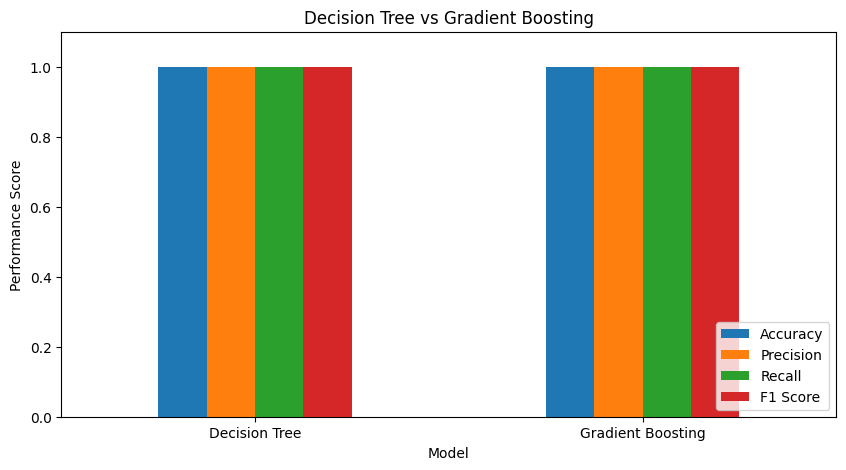

Selected model: Decision Tree


In [12]:

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Decision Tree vs Gradient Boosting")
plt.ylabel("Performance Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

best_model_name = max(
    results,
    key=lambda x: (x["Recall"], x["F1 Score"])
)["Model"]

best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

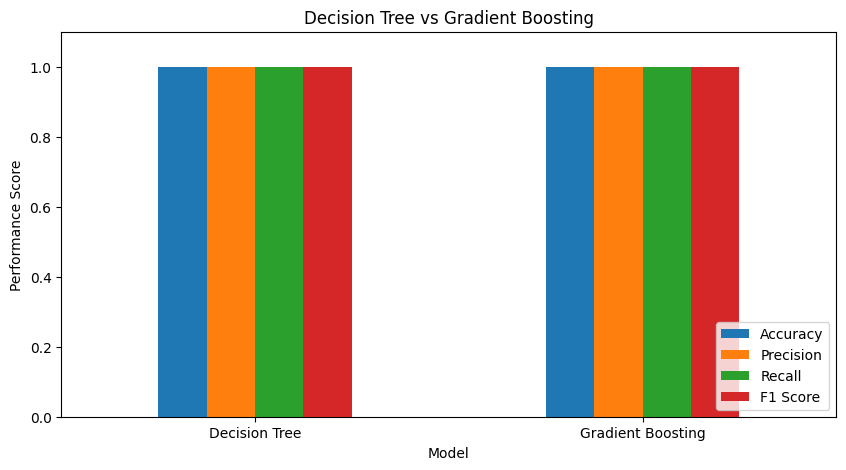

Selected model: Decision Tree


In [15]:

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Decision Tree vs Gradient Boosting")
plt.ylabel("Performance Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

best_model_name = max(
    results,
    key=lambda x: (x["Recall"], x["F1 Score"])
)["Model"]

best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

In [17]:

!pip install -q --upgrade mlflow scikit-learn cloudpickle


In [18]:

import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_registry_uri("sqlite:///mlflow.db")

mlflow.set_experiment("Railway_Bus_MLOps")

for name, pipeline in trained_models.items():

    row = results_df[results_df["Model"] == name].iloc[0]

    with mlflow.start_run(run_name=name):

        mlflow.log_param("model_name", name)
        mlflow.log_param("dataset", "Version_2_Peak_Hour")

        mlflow.log_metric("accuracy", float(row["Accuracy"]))
        mlflow.log_metric("precision", float(row["Precision"]))
        mlflow.log_metric("recall", float(row["Recall"]))
        mlflow.log_metric("f1_score", float(row["F1 Score"]))

        mlflow.sklearn.log_model(
            sk_model=pipeline,
            artifact_path="model",
            serialization_format="cloudpickle"
        )

print("MLflow tracking completed successfully!")


2026/11/18 08:58:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 08:58:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/18 08:58:31 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmpdbtxc1ud/model/model.pkl, flavor: sklearn). Fall back to return ['scikit-learn==1.9.1', 'cloudpickle==3.1.2']. Set logging level to DEBUG to see the full traceback. 
2026/11/18 08:58:31 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 08:58:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pi

MLflow tracking completed successfully!


In [19]:

with mlflow.start_run(run_name="Selected_Model_Registration"):

    model_info = mlflow.sklearn.log_model(
        sk_model=best_model,
        artifact_path="selected_model",
        serialization_format="cloudpickle",
        registered_model_name="RailwayBusConnectionModel"
    )

    mlflow.log_param("selected_model", best_model_name)

    mlflow.log_param(
        "selection_criteria",
        "Highest recall followed by F1 score"
    )

print("Model registered successfully!")

print("Registered model URI:", model_info.model_uri)


2026/11/18 08:59:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/18 08:59:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/18 08:59:15 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmprhcuyzj3/model/model.pkl, flavor: sklearn). Fall back to return ['scikit-learn==1.9.1', 'cloudpickle==3.1.2']. Set logging level to DEBUG to see the full traceback. 


Model registered successfully!
Registered model URI: models:/m-05e4de63813c4ec3924ee794ce5b13f1


Successfully registered model 'RailwayBusConnectionModel'.
Created version '1' of model 'RailwayBusConnectionModel'.


In [20]:

!nohup mlflow ui \
    --backend-store-uri sqlite:///mlflow.db \
    --host 0.0.0.0 \
    --port 5000 > mlflow.log 2>&1 &

print("MLflow dashboard started!")


MLflow dashboard started!


In [21]:

loaded_model = mlflow.sklearn.load_model(
    model_info.model_uri
)

print("Model loaded successfully!")

print("Selected model:", best_model_name)


Model loaded successfully!
Selected model: Decision Tree
